---
### 🐛 Found a bug or have a suggestion?
[Open a GitHub Issue](https://github.com/ladataanalytics/pattern-recognition-notebooks/issues/new?template=bug_report.md) — describe the notebook name, cell number, and what went wrong.
*Search [existing issues](https://github.com/ladataanalytics/pattern-recognition-notebooks/issues) first to avoid duplicates.*

### 💾 Save your own copy
> **File → Save a copy in Drive** — this saves a personal copy to *your* Google Drive so your work is preserved.
> You must do this before making edits, otherwise changes are lost when the session ends.

# ⚡ Boosting
**ISLP Chapter 8 · Pattern Recognition for the Rest of Us**

> While Random Forests train trees independently and average them, Boosting trains trees *sequentially* — each tree learns from the mistakes of the previous one. This iterative error-correction makes Boosting one of the highest-performing ML approaches.

### What you'll learn
- AdaBoost — upweighting misclassified points
- Gradient Boosting — fitting trees to residuals
- XGBoost — the industry-standard implementation
- Key hyperparameters: n_estimators, learning_rate, max_depth
- Comparing Boosting vs Random Forests

### Dataset: California Housing (regression) + Heart disease (classification)

# 🚀 Gradient Boosting
**ISLP Chapter 8 · Pattern Recognition for the Rest of Us**

> Jump in — each section builds on the last. Run cells top to bottom with Shift+Enter.

### What you'll learn
- How boosting builds models sequentially
- Gradient Boosting Machines (GBM)
- Key hyperparameters: n_estimators, learning_rate, max_depth
- Feature importance and partial dependence

### Time: ~50 minutes

In [1]:
# ⚠️  Run this cell first — sets up data and imports
# Tip: Runtime → Run all  (runs everything top to bottom automatically)

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': '#f8f9fa',
    'axes.grid': True, 'grid.alpha': 0.4,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 11
})

from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.datasets import fetch_california_housing

# ── Load / generate data ──────────────────────────────────────────────────────
# California Housing via sklearn
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing()
X_raw = pd.DataFrame(data.data, columns=data.feature_names)
y_raw = pd.Series(data.target, name="MedHouseVal")
print(f"✓ California Housing: {X_raw.shape}")

print(f'  Python {sys.version.split()[0]} | pandas {pd.__version__}')
print('✓ Setup complete')


✓ California Housing: (20640, 8)
  Python 3.13.16 | pandas 2.2.3
✓ Setup complete


In [2]:
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing(as_frame=True)
df_house = data.frame
X = df_house.drop('MedHouseVal', axis=1)
y = df_house['MedHouseVal']
print(f"California Housing: {df_house.shape}")
df_house.head()

California Housing: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Load California Housing
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing(as_frame=True)
df_house = data.frame
X = df_house.drop('MedHouseVal', axis=1)
y = df_house['MedHouseVal']

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"California Housing: {X.shape[0]:,} census blocks")
print(f"Predicting: median house value (in $100,000s)")
print(f"Features: {list(X.columns)}")

California Housing: 20,640 census blocks
Predicting: median house value (in $100,000s)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


## ⚡ Part 1 — How Gradient Boosting Works

**Core idea:** Train trees sequentially. Each tree fits the *residuals* (errors) from all previous trees.

**Step by step:**
1. Initialize with a simple prediction (e.g. mean of Y)
2. Compute residuals: rᵢ = yᵢ - ŷᵢ
3. Fit a small tree to the residuals
4. Update: ŷᵢ ← ŷᵢ + λ × (tree prediction)  (λ = learning rate, shrinks each step)
5. Repeat 2-4 for B iterations

The **learning rate** (shrinkage) λ is critical — small λ requires more trees but generalizes better.

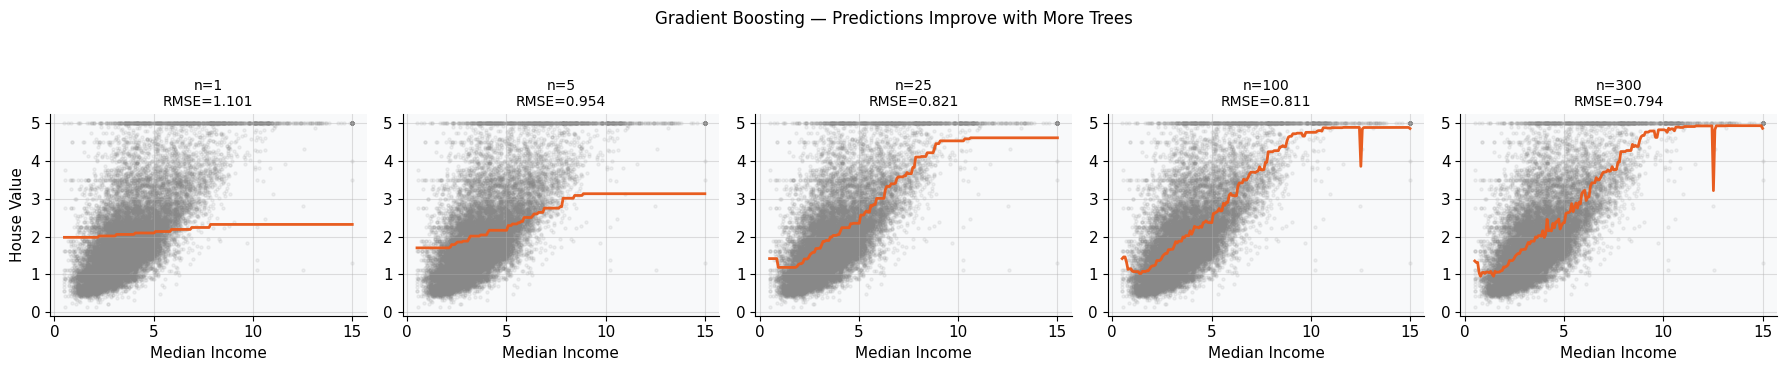

In [4]:
# Show boosting building up — predictions improve with each tree
from sklearn.ensemble import GradientBoostingRegressor

stages = [1, 5, 25, 100, 300]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))

# Use a small 1D slice for visualization
X_viz = X_tr[['MedInc']].copy()
y_viz = y_tr.values

for ax, n in zip(axes, stages):
    gbm = GradientBoostingRegressor(n_estimators=n, learning_rate=0.1,
                                     max_depth=3, random_state=42)
    gbm.fit(X_viz, y_viz)

    xi = np.linspace(X_viz['MedInc'].min(), X_viz['MedInc'].max(), 200).reshape(-1,1)
    yi_pred = gbm.predict(xi)

    ax.scatter(X_viz['MedInc'], y_viz, alpha=0.1, s=5, color='#888')
    ax.plot(xi, yi_pred, color='#e85d20', lw=2)
    mse = mean_squared_error(y_viz, gbm.predict(X_viz))
    ax.set_title(f'n={n}\nRMSE={np.sqrt(mse):.3f}', fontsize=10)
    ax.set_xlabel('Median Income')
    if n==1: ax.set_ylabel('House Value')

plt.suptitle('Gradient Boosting — Predictions Improve with More Trees', y=1.05, fontsize=12)
plt.tight_layout()
plt.show()

Gradient Boosting (sklearn) is the reference implementation. It fits trees one at a time, each on the residuals of the ensemble so far. Solid and well-understood but slow — it's purely sequential and can't be parallelized.
XGBoost is an optimized re-implementation of the same algorithm with several improvements:

Speed — parallelizes the split-finding step, caches data layout for faster access. Typically 5–10x faster than sklearn GBM on the same data.
Regularization — adds L1 and L2 penalties on leaf weights directly in the objective function, not just via tree depth. Gives you more levers to control overfitting.
Sparsity handling — learns a default direction for missing values automatically, so you don't need to impute before fitting.
Approximate split finding — uses quantile sketches instead of evaluating every possible split, which matters at scale.

In [5]:
import xgboost as xgb
# Compare: sklearn GBM vs XGBoost
from sklearn.metrics import mean_squared_error as mse

models = {
    'GBM (sklearn)': GradientBoostingRegressor(n_estimators=300, learning_rate=0.1,
                                                max_depth=4, random_state=42),
    'XGBoost': xgb.XGBRegressor(n_estimators=300, learning_rate=0.1,
                                  max_depth=4, random_state=42,
                                  eval_metric='rmse', verbosity=0),
}

print(f"{'Model':<20} {'Train RMSE':>12} {'Test RMSE':>12}")
print("-"*45)
for name, model in models.items():
    model.fit(X_tr, y_tr)
    tr_rmse = np.sqrt(mse(y_tr, model.predict(X_tr)))
    te_rmse = np.sqrt(mse(y_te, model.predict(X_te)))
    print(f"{name:<20} {tr_rmse:>12.4f} {te_rmse:>12.4f}")
print("\n📌 XGBoost uses second-order gradients, regularization, and parallel computing")
print("   — often faster and slightly better than sklearn's GBM")

Model                  Train RMSE    Test RMSE
---------------------------------------------
GBM (sklearn)              0.3848       0.4774
XGBoost                    0.3928       0.4696

📌 XGBoost uses second-order gradients, regularization, and parallel computing
   — often faster and slightly better than sklearn's GBM


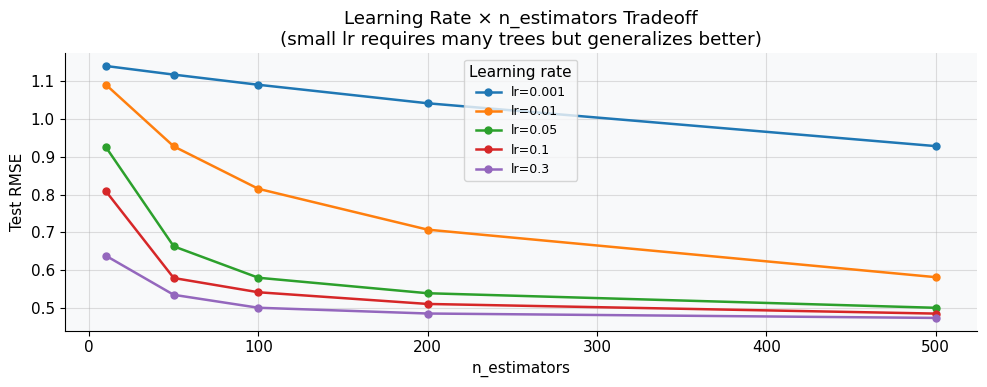


📌 Small learning rate (0.01) + many trees often outperforms large lr + few trees
   But small lr is slower to train — XGBoost's early stopping solves this


In [6]:
# Effect of learning rate and n_estimators (the key tradeoff)
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.3]
n_estimators   = [10, 50, 100, 200, 500]
results = np.zeros((len(learning_rates), len(n_estimators)))

for i, lr in enumerate(learning_rates):
    for j, n in enumerate(n_estimators):
        gbm = GradientBoostingRegressor(n_estimators=n, learning_rate=lr,
                                         max_depth=3, random_state=42)
        gbm.fit(X_tr, y_tr)
        results[i,j] = np.sqrt(mse(y_te, gbm.predict(X_te)))

fig, ax = plt.subplots(figsize=(10, 4))
for i, lr in enumerate(learning_rates):
    ax.plot(n_estimators, results[i], 'o-', lw=1.8, markersize=5,
            label=f'lr={lr}')
ax.set_xlabel('n_estimators')
ax.set_ylabel('Test RMSE')
ax.set_title('Learning Rate × n_estimators Tradeoff\n(small lr requires many trees but generalizes better)')
ax.legend(title='Learning rate', fontsize=9)
plt.tight_layout()
plt.show()
print("\n📌 Small learning rate (0.01) + many trees often outperforms large lr + few trees")
print("   But small lr is slower to train — XGBoost's early stopping solves this")

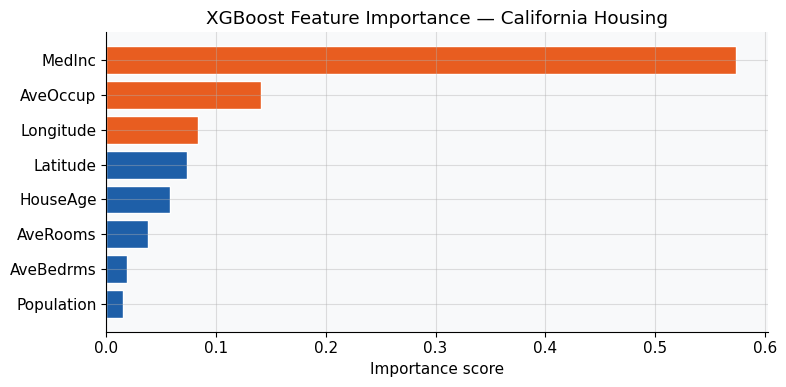


Final XGBoost Test RMSE: 0.4763
📌 MedInc (median income) dominates — wealthy neighborhoods = higher house values


In [7]:
# Feature importance (XGBoost)
xgb_model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05,
                               max_depth=4, random_state=42, verbosity=0)
xgb_model.fit(X_tr, y_tr)

imp = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#e85d20' if v > imp.quantile(0.6) else '#1e5fa8' for v in imp]
ax.barh(imp.index, imp.values, color=colors, edgecolor='white')
ax.set_title('XGBoost Feature Importance — California Housing')
ax.set_xlabel('Importance score')
plt.tight_layout()
plt.show()
final_rmse = np.sqrt(mse(y_te, xgb_model.predict(X_te)))
print(f"\nFinal XGBoost Test RMSE: {final_rmse:.4f}")
print("📌 MedInc (median income) dominates — wealthy neighborhoods = higher house values")

## 💼 Exercise

Using the California Housing dataset, compare a single Decision Tree, Random Forest, and Gradient Boosting Regressor. Use the same train/test split. Which has the lowest test RMSE? Plot learning curves (test error vs n_estimators) for the GBM.

In [8]:
# ── Exercise workspace ──────────────────────────────────────────────────────
# Write your code here



In [9]:
# @title 📝 Quiz — Boosting
# @markdown Answer each question in the box below, then run the AI grading cell.

# @markdown **Q1:** What is the core difference between Random Forest and Gradient Boosting?
# @markdown **Q2:** What does the learning rate control in gradient boosting?
# @markdown **Q3:** Why does a very high learning rate (e.g. 0.9) often perform poorly?
# @markdown **Q4:** What is the advantage of XGBoost over sklearn's GradientBoosting?
# @markdown **Q5:** If your boosting model overfits, name two hyperparameters you would adjust

q1 = "" # @param {type:"string", placeholder:"your answer"}
q2 = "" # @param {type:"string", placeholder:"your answer"}
q3 = "" # @param {type:"string", placeholder:"your answer"}
q4 = "" # @param {type:"string", placeholder:"your answer"}
q5 = "" # @param {type:"string", placeholder:"your answer"}

# Collect into answers dict for grading cell
answers = {"q1": q1, "q2": q2, "q3": q3, "q4": q4, "q5": q5}
missing = [k for k,v in answers.items() if not str(v).strip()]
print(f"  {5-len(missing)}/5 answered — run the AI grading cell below for feedback")

  0/5 answered — run the AI grading cell below for feedback


### 📤 Submit your results

In [10]:
_NB_NAME_="Boosting"
# @title 📋 Quiz Submission
# @markdown **Click ▶ Run** → copy the output box (click the copy icon in the top-left of the output box, or click ⋮ → Copy) → paste into Gemini in this Colab session.

GITHUB_USERNAME = "" # @param {type:"string", placeholder:"your GitHub username e.g. jsmith42"}

_NB_TITLE = globals().get("_NB_NAME_", "this notebook")

if "answers" not in globals():
    print("Run the quiz cell above first, then re-run this cell.")
else:
    qa = "\n".join(
        f"Q{i}: {str(v).strip() or '(no answer)'}"
        for i, (_, v) in enumerate(answers.items(), 1)
    )
    print(f"Please grade my quiz answers for the \"{_NB_TITLE}\" notebook")
    print(f"from \"Data Pattern Recognition for the Rest of Us\" (based on ISLP).")
    if GITHUB_USERNAME.strip():
        print(f"Student: @{GITHUB_USERNAME.strip()}")
    print()
    print(qa)
    print()
    print("For each question:")
    print("  1. Say CORRECT, PARTIAL, or INCORRECT")
    print("  2. Explain in 2-3 sentences why — what did I get right or wrong")
    print("  3. Give the ideal complete answer so I know exactly what was expected")
    print("  4. If I was wrong or partial, tell me the specific concept to review")
    print("     and where it appears in the notebook (e.g. Part 2, the SHAP beeswarm plot)")
    print()
    print("End with:")
    print("  - Overall grade: Excellent / Good / Needs Review / Incomplete")
    print("  - A short study plan: which questions to re-read and what to focus on")
    print()
    print("After grading, I will paste specific outputs, charts, or code blocks")
    print("from the notebook — please explain them in detail and answer follow-up questions.")


Please grade my quiz answers for the "Boosting" notebook
from "Data Pattern Recognition for the Rest of Us" (based on ISLP).

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)

For each question:
  1. Say CORRECT, PARTIAL, or INCORRECT
  2. Explain in 2-3 sentences why — what did I get right or wrong
  3. Give the ideal complete answer so I know exactly what was expected
  4. If I was wrong or partial, tell me the specific concept to review
     and where it appears in the notebook (e.g. Part 2, the SHAP beeswarm plot)

End with:
  - Overall grade: Excellent / Good / Needs Review / Incomplete
  - A short study plan: which questions to re-read and what to focus on

After grading, I will paste specific outputs, charts, or code blocks
from the notebook — please explain them in detail and answer follow-up questions.


---
### 🐛 Found a bug or have a suggestion?
[Open a GitHub Issue](https://github.com/ladataanalytics/pattern-recognition-notebooks/issues/new?template=bug_report.md) — describe the notebook name, cell number, and what went wrong.
*Search [existing issues](https://github.com/ladataanalytics/pattern-recognition-notebooks/issues) first to avoid duplicates.*

---
*Data Pattern Recognition for the Rest of Us · [ladataanalytics.github.io/pattern-recognition-notebooks](https://ladataanalytics.github.io/pattern-recognition-notebooks)*

In [11]:
!pip install -q lazypredict

import pandas as pd
from sklearn.model_selection import train_test_split
from lazypredict.Supervised import LazyRegressor

# Sample 1000 records from our existing df_house dataset
df_sample = df_house.sample(n=1000, random_state=42)
X_sample = df_sample.drop('MedHouseVal', axis=1)
y_sample = df_sample['MedHouseVal']

# Split the sampled data into training and testing sets
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_sample, y_sample, test_size=0.2, random_state=42)

# Initialize and fit LazyRegressor
lazy_reg = LazyRegressor(verbose=0, ignore_warnings=True, custom_metric=None)
models, predictions = lazy_reg.fit(X_train_s, X_test_s, y_train_s, y_test_s)

# Display the top models
print(models)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.0/71.0 kB 6.4 MB/s eta 0:00:00
                               Adjusted R-Squared  R-Squared      RMSE  \
Model                                                                    
LGBMRegressor                            0.706657   0.718450  0.654346   
MLPRegressor                             0.704391   0.716275  0.656868   
NuSVR                                    0.694008   0.706309  0.668305   
SVR                                      0.693879   0.706185  0.668446   
HistGradientBoostingRegressor            0.692792   0.705142  0.669632   
RandomForestRegressor                    0.675137   0.688197  0.688605   
ExtraTreesRegressor                      0.673460   0.686587  0.690380   
OrthogonalMatchingPursuitCV              0.658377   0.672111  0.706144   
GradientBoostingRegressor                0.657127   0.670911  0.707435   
BaggingRegressor                         0.656620   0.670424  0.707958   
LassoCV                           